# Clima vs Roya del cafeto 2016–2018
Chiapas, Puebla y Veracruz. Roya: excel Clima: NASA POWER.

In [ ]:
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

ESTADOS = ["Chiapas", "Puebla", "Veracruz"]
VARS = ["humedad", "precip", "temp"]
NOMBRES = {"humedad": "Humedad rel. (%)", "precip": "Precipitación (mm/mes)", "temp": "Temperatura media (°C)"}

ARCHIVOS = {
    "RoyaCafe_2016.xlsx": [2016],
    "RoyaCafe_2018.xlsx": [2018],
    "RoyaCafe_2018_Y_2017.xlsx": [2018, 2017],   # primer bloque 2018, segundo 2017
}

## 1. Roya

In [ ]:
MESES = {"enero": 1, "febrero": 2, "marzo": 3, "abril": 4, "mayo": 5, "junio": 6, "julio": 7,
         "agosto": 8, "septiembre": 9, "octubre": 10, "noviembre": 11, "diciembre": 12}
COLS = ["planta", "var_planta", "hoja", "var_hoja"]

def leer_hoja(ruta, hoja):
    # una hoja puede traer más de un año: devuelve (mensual, semanal) por bloque
    crudo = pd.read_excel(ruta, sheet_name=hoja, header=None)
    inicios = [i for i in range(len(crudo)) if crudo.iloc[i].astype(str).str.contains("Promedio Mensual").any()]
    inicios.append(len(crudo))
    bloques = []
    for ini, fin in zip(inicios[:-1], inicios[1:]):
        mensual, semanal = [], []
        for i in range(ini, fin):
            fila = crudo.iloc[i].tolist()
            # mensual: nombre del mes en la parte derecha + 4 valores
            cols_mes = [j for j, v in enumerate(fila) if isinstance(v, str) and v.strip().lower() in MESES and j >= 7]
            if cols_mes:
                j = cols_mes[-1]
                mensual.append([MESES[fila[j].strip().lower()]] + fila[j + 1:j + 5])
            # semanal: numero de semana en las primeras columnas
            for j in range(4):
                v = fila[j]
                if isinstance(v, (int, float)) and not pd.isna(v) and 1 <= v <= 52 and float(v).is_integer():
                    semanal.append([int(v)] + fila[j + 1:j + 5])
                    break
        mensual = pd.DataFrame(mensual, columns=["mes"] + COLS)
        semanal = pd.DataFrame(semanal, columns=["semana"] + COLS)
        for t in (mensual, semanal):
            t[COLS] = t[COLS].apply(pd.to_numeric, errors="coerce")
        bloques.append((mensual, semanal))
    return bloques

def quitar_ceros(mensual, semanal, nombre):
    # hay semanas con todo en 0  que el excel metió al promedio del mes
    # se busca la ventana de 4-5 semanas que da ese promedio y se recalcula sin el cero
    mensual = mensual.copy()
    semanal = semanal.reset_index(drop=True)
    for z in semanal.index[(semanal.planta == 0) & (semanal.hoja == 0)]:
        for tam in (4, 5):
            for ini in range(max(0, z - tam + 1), z + 1):
                ventana = semanal.iloc[ini:ini + tam]
                if len(ventana) < tam:
                    continue
                coincide = mensual[((mensual.planta - ventana.planta.mean()).abs() < 0.02) &
                                   ((mensual.hoja - ventana.hoja.mean()).abs() < 0.02)]
                if len(coincide) == 1:
                    sin_cero = ventana[~((ventana.planta == 0) & (ventana.hoja == 0))]
                    mes = coincide.mes.iloc[0]
                    print(f"{nombre}: semana {semanal.semana[z]} en cero, mes {mes}: "
                          f"{coincide.planta.iloc[0]:.2f} -> {sin_cero.planta.mean():.2f}")
                    mensual.loc[coincide.index, "planta"] = sin_cero.planta.mean()
                    mensual.loc[coincide.index, "hoja"] = sin_cero.hoja.mean()
    # mes completo en cero = sin datos
    sin_dato = (mensual.planta == 0) & (mensual.hoja == 0)
    mensual.loc[sin_dato, ["planta", "hoja"]] = np.nan
    return mensual

In [ ]:
partes = []
for archivo, anios in ARCHIVOS.items():
    for estado in ESTADOS:
        bloques = leer_hoja(os.path.join("", archivo), estado)
        assert len(bloques) == len(anios), f"{archivo} / {estado}: esperaba {len(anios)} bloques y hay {len(bloques)}"
        for anio, (mensual, semanal) in zip(anios, bloques):
            m = quitar_ceros(mensual, semanal, f"{estado} {anio}")
            partes.append(m.assign(estado=estado, anio=anio))

roya = pd.concat(partes, ignore_index=True)
roya["fecha"] = pd.to_datetime(dict(year=roya.anio, month=roya.mes, day=1))
roya = roya.rename(columns={"planta": "roya_planta", "hoja": "roya_hoja"})

# 2018 viene en dos archivos: deben ser iguales
dup = roya[roya.duplicated(["estado", "fecha"], keep=False)]
assert (dup.groupby(["estado", "fecha"])[["roya_planta", "roya_hoja"]].nunique(dropna=False) == 1).all().all()
roya = (roya.drop_duplicates(["estado", "fecha"])
            .sort_values(["estado", "fecha"])
            [["estado", "fecha", "anio", "mes", "roya_planta", "roya_hoja"]]
            .reset_index(drop=True))
assert len(roya) == 108
print("meses sin dato:", roya.roya_planta.isna().sum())
roya.head(80)

Veracruz 2018: semana 52 en cero, mes 12: 18.68 -> 24.90
Puebla 2017: semana 36 en cero, mes 9: 15.92 -> 21.23
Veracruz 2018: semana 52 en cero, mes 12: 18.68 -> 24.90
Veracruz 2017: semana 36 en cero, mes 9: 15.25 -> 20.33
meses sin dato: 6


,estado,fecha,anio,mes,roya_planta,roya_hoja
0,Chiapas,2016-01-01,2016,1,NaN,NaN
1,Chiapas,2016-02-01,2016,2,10.920000,6.620000
2,Chiapas,2016-03-01,2016,3,6.220000,2.720000
3,Chiapas,2016-04-01,2016,4,4.480000,1.520000
4,Chiapas,2016-05-01,2016,5,2.983333,0.933333
...,...,...,...,...,...,...
75,Veracruz,2016-04-01,2016,4,8.940000,2.720000
76,Veracruz,2016-05-01,2016,5,5.416667,1.133333
77,Veracruz,2016-06-01,2016,6,5.020000,1.000000
78,Veracruz,2016-07-01,2016,7,5.460000,1.180000


In [ ]:
# severidad en planta por mes y año
roya.pivot_table(index="mes", columns=["estado", "anio"], values="roya_planta").round(1)

estado Chiapas             Puebla             Veracruz            
anio      2016  2017  2018   2016  2017  2018     2016  2017  2018
mes                                                               
1          NaN   NaN  11.2    NaN   NaN  24.8      NaN   NaN  34.6
2         10.9  11.1   7.1   19.2  22.8  20.6     23.4  27.8  27.0
3          6.2   6.8   4.4    9.4  18.7  15.9     16.8  18.4  17.5
4          4.5   4.2   2.3   10.0  11.7   9.4      8.9   7.1   7.2
5          3.0   2.3   2.0    7.7   8.9   9.0      5.4   4.1   7.1
6          2.6   2.0   2.2    7.6   7.8  12.1      5.0   4.0   9.7
7          2.8   3.2   3.2    9.3  12.0  14.1      5.5   7.6  12.4
8          3.9   7.2   4.4   17.2  19.7  17.0      7.0  15.1  15.4
9          5.1   7.4   5.6   23.8  21.2  17.4     12.7  20.3  18.1
10         6.7   9.2   7.4   27.5  25.5  18.7     20.0  27.3  22.0
11         7.7  12.0  10.6   27.0  29.4  16.9     22.2  34.4  25.7
12         9.3  11.7  12.2   23.0  26.8  17.8     22.5  29.9  24.9

##  Clima

In [ ]:
URL = "https://power.larc.nasa.gov/api/temporal/monthly/point"

# dos puntos cafetaleros por estado (coordenadas aproximadas)
PUNTOS = {
    "Chiapas":  [("Soconusco", 15.00, -92.17), ("Altos", 16.79, -92.35)],
    "Puebla":   [("Cuetzalan", 20.02, -97.52), ("Xicotepec", 20.28, -97.96)],
    "Veracruz": [("Coatepec", 19.45, -96.96), ("Huatusco", 19.15, -96.97)],
}

def bajar_clima(lat, lon, desde=2015, hasta=2018):
    # se baja desde 2015 para tener clima de los meses previos a ene-2016
    archivo = f"clima_{lat:.2f}_{lon:.2f}_{desde}_{hasta}.csv"
    if os.path.exists(archivo):
        return pd.read_csv(archivo, parse_dates=["fecha"])
    params = {"parameters": "T2M,RH2M,PRECTOTCORR", "community": "AG", "longitude": lon,
              "latitude": lat, "start": desde, "end": hasta, "format": "JSON"}
    r = requests.get(URL, params=params, timeout=90)
    r.raise_for_status()
    d = pd.DataFrame(r.json()["properties"]["parameter"])
    d = d[~d.index.str.endswith("13")]                  # la fila 13 es el promedio anual
    d.index = pd.to_datetime(d.index, format="%Y%m")
    d = d.replace(-999, np.nan).rename(columns={"T2M": "temp", "RH2M": "humedad", "PRECTOTCORR": "precip"})
    d["precip"] = d["precip"] * d.index.days_in_month.values   # mm/día -> mm/mes
    d = d.rename_axis("fecha").reset_index()
    d.to_csv(archivo, index=False)
    return d

partes = []
for estado, lista in PUNTOS.items():
    for nombre, lat, lon in lista:
        partes.append(bajar_clima(lat, lon).assign(estado=estado, punto=nombre))
clima_puntos = pd.concat(partes, ignore_index=True)

# clima del estado = promedio de sus puntos
clima = clima_puntos.groupby(["estado", "fecha"], as_index=False)[VARS].mean()
clima["anio"], clima["mes"] = clima.fecha.dt.year, clima.fecha.dt.month
print(clima_puntos.shape, clima.shape)
clima_puntos.head(800)

(288, 6) (144, 7)


,fecha,precip,humedad,temp,estado,punto
0,2015-01-01,3.41,78.71,16.68,Chiapas,Soconusco
1,2015-02-01,3.08,74.93,17.71,Chiapas,Soconusco
2,2015-03-01,48.05,73.57,18.83,Chiapas,Soconusco
3,2015-04-01,130.50,78.34,20.22,Chiapas,Soconusco
4,2015-05-01,246.76,83.38,19.92,Chiapas,Soconusco
...,...,...,...,...,...,...
283,2018-08-01,257.61,81.22,20.40,Veracruz,Huatusco
284,2018-09-01,205.50,85.57,20.72,Veracruz,Huatusco
285,2018-10-01,254.82,87.59,19.80,Veracruz,Huatusco
286,2018-11-01,63.00,85.62,17.24,Veracruz,Huatusco


In [ ]:
# resumen por estado
clima.groupby("estado")[VARS].agg(["mean", "min", "max"]).round(1)

humedad             precip               temp            
            mean   min   max   mean   min    max  mean   min   max
estado                                                            
Chiapas     83.4  73.2  89.9  174.4  15.7  465.2  19.1  15.2  21.7
Puebla      78.8  60.1  89.0  115.8   7.4  441.3  19.2  12.0  23.9
Veracruz    79.7  64.4  89.7  123.4  12.1  374.8  19.3  13.4  23.5

In [ ]:
# precipitación (mm) por año y mes
clima.pivot_table(index=["estado", "anio"], columns="mes", values="precip").round(0)

mes               1     2      3      4      5      6      7      8      9   \
estado   anio                                                                 
Chiapas  2015   89.0  35.0   56.0  111.0  167.0  185.0  149.0  218.0  389.0   
         2016   27.0  37.0   35.0   38.0  226.0  289.0  195.0  302.0  362.0   
         2017   19.0  16.0   43.0   84.0  324.0  465.0  255.0  258.0  435.0   
         2018  110.0  20.0   42.0  176.0  238.0  309.0  144.0  283.0  356.0   
Puebla   2015   75.0  24.0  132.0   75.0   87.0  130.0  124.0  124.0  199.0   
         2016   23.0   7.0   44.0   53.0   47.0  251.0  169.0  218.0  229.0   
         2017   10.0  32.0   56.0   37.0  120.0  141.0  190.0  209.0  441.0   
         2018   80.0  30.0   66.0  121.0   42.0  158.0   82.0  192.0  148.0   
Veracruz 2015   63.0  17.0  119.0   76.0   84.0  164.0  163.0  165.0  234.0   
         2016   25.0  15.0   46.0   55.0   55.0  239.0  218.0  293.0  230.0   
         2017   12.0  24.0   62.0   50.0  115.0  218.0  221.0  295.0  375.0   
         2018   70.0  27.0   71.0  100.0   45.0  185.0  108.0  241.0  188.0   

mes               10     11    12  
estado   anio                      
Chiapas  2015  343.0  205.0  88.0  
         2016  246.0  142.0  40.0  
         2017  279.0   64.0  27.0  
         2018  292.0  111.0  49.0  
Puebla   2015  162.0  176.0  24.0  
         2016  182.0  132.0  73.0  
         2017  240.0   23.0  25.0  
         2018  265.0   60.0  28.0  
Veracruz 2015  142.0  157.0  22.0  
         2016  156.0   90.0  73.0  
         2017  210.0   31.0  24.0  
         2018  242.0   68.0  39.0

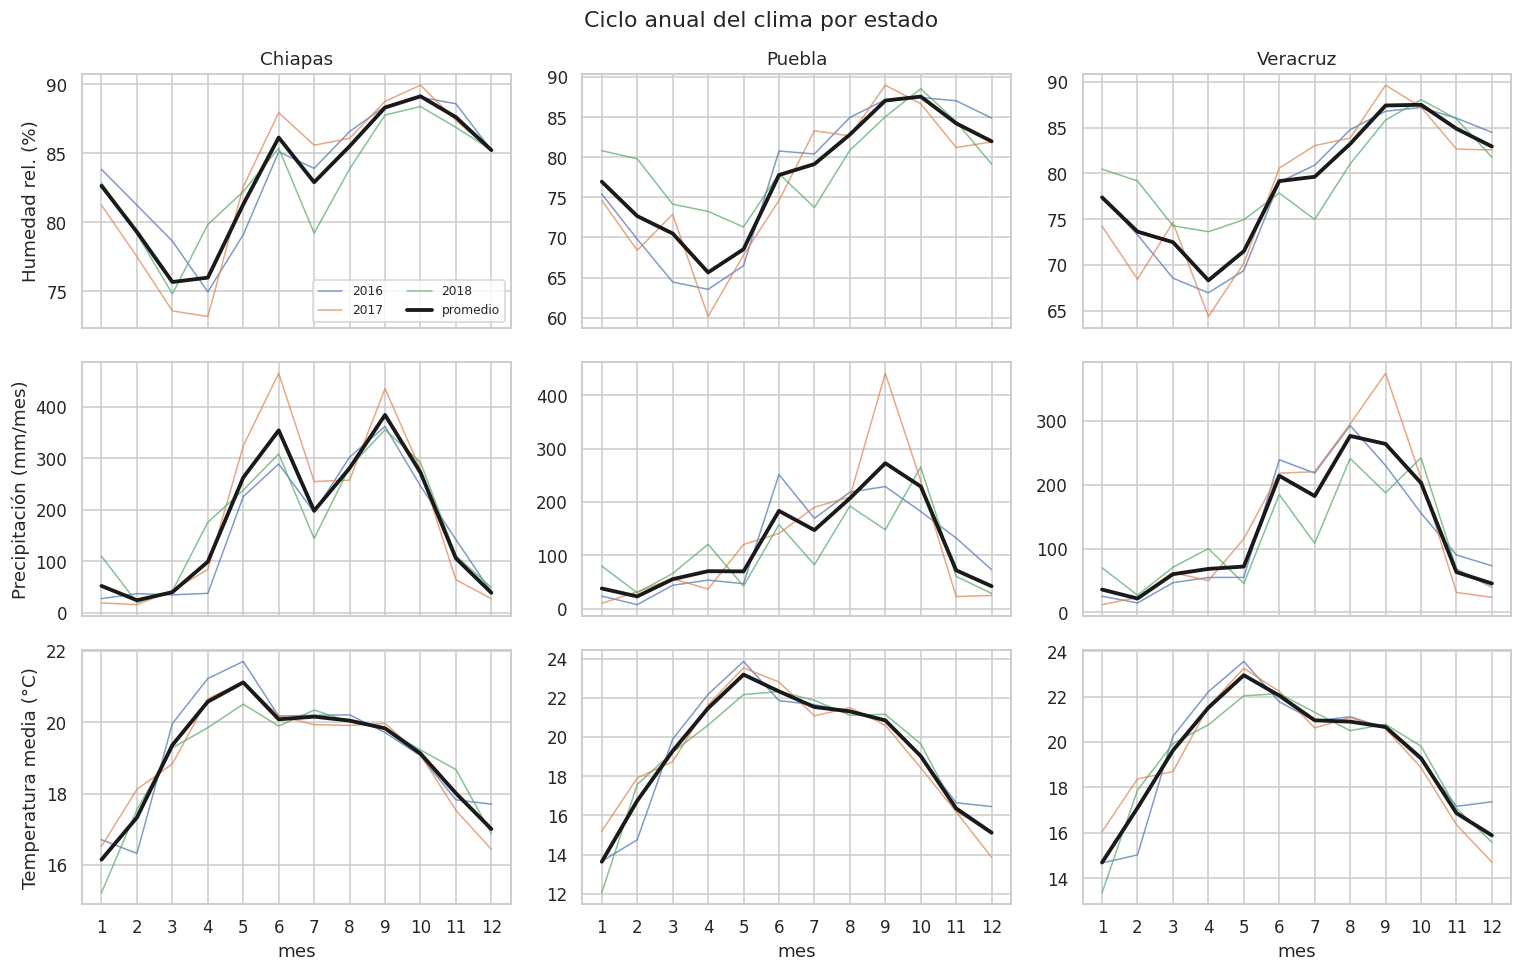

In [ ]:
c = clima[clima.anio.between(2016, 2018)]
fig, ejes = plt.subplots(3, 3, figsize=(14, 9), sharex=True)
for i, v in enumerate(VARS):
    for j, est in enumerate(ESTADOS):
        ax = ejes[i, j]
        ce = c[c.estado == est]
        for anio, g in ce.groupby("anio"):
            ax.plot(g.mes, g[v], lw=1, alpha=.7, label=anio)
        ax.plot(range(1, 13), ce.groupby("mes")[v].mean(), "k-", lw=2.5, label="promedio")
        if i == 0: ax.set_title(est)
        if j == 0: ax.set_ylabel(NOMBRES[v])
        if i == 2: ax.set_xlabel("mes"); ax.set_xticks(range(1, 13))
ejes[0, 0].legend(fontsize=8, ncol=2)
fig.suptitle("Ciclo anual del clima por estado")
fig.tight_layout(); plt.show()

## 3. Roya vs clima

In [ ]:
LAGS = range(0, 7)

def agregar_rezagos(clima):
    # por estado: clima de hace k meses, y su anomalía (valor - promedio de ese mes)
    salida = []
    for est, g in clima.groupby("estado"):
        g = g.sort_values("fecha").reset_index(drop=True)
        for v in VARS:
            anom = g[v] - g.groupby("mes")[v].transform("mean")
            for k in LAGS:
                g[f"{v}_{k}"] = g[v].shift(k)
                g[f"{v}_{k}_anom"] = anom.shift(k)
        salida.append(g.drop(columns=["anio", "mes"]))
    return pd.concat(salida, ignore_index=True)

datos = roya.merge(agregar_rezagos(clima), on=["estado", "fecha"], how="left")
print(datos.shape)
datos[["estado", "fecha", "roya_planta", "humedad", "precip", "temp", "precip_3"]].head()

(108, 51)


,estado,fecha,roya_planta,humedad,precip,temp,precip_3
0,Chiapas,2016-01-01,NaN,83.835,27.280,16.705,342.705
1,Chiapas,2016-02-01,10.920000,81.250,37.120,16.320,204.750
2,Chiapas,2016-03-01,6.220000,78.645,34.720,19.965,87.730
3,Chiapas,2016-04-01,4.480000,74.970,37.650,21.230,27.280
4,Chiapas,2016-05-01,2.983333,79.110,225.525,21.710,37.120


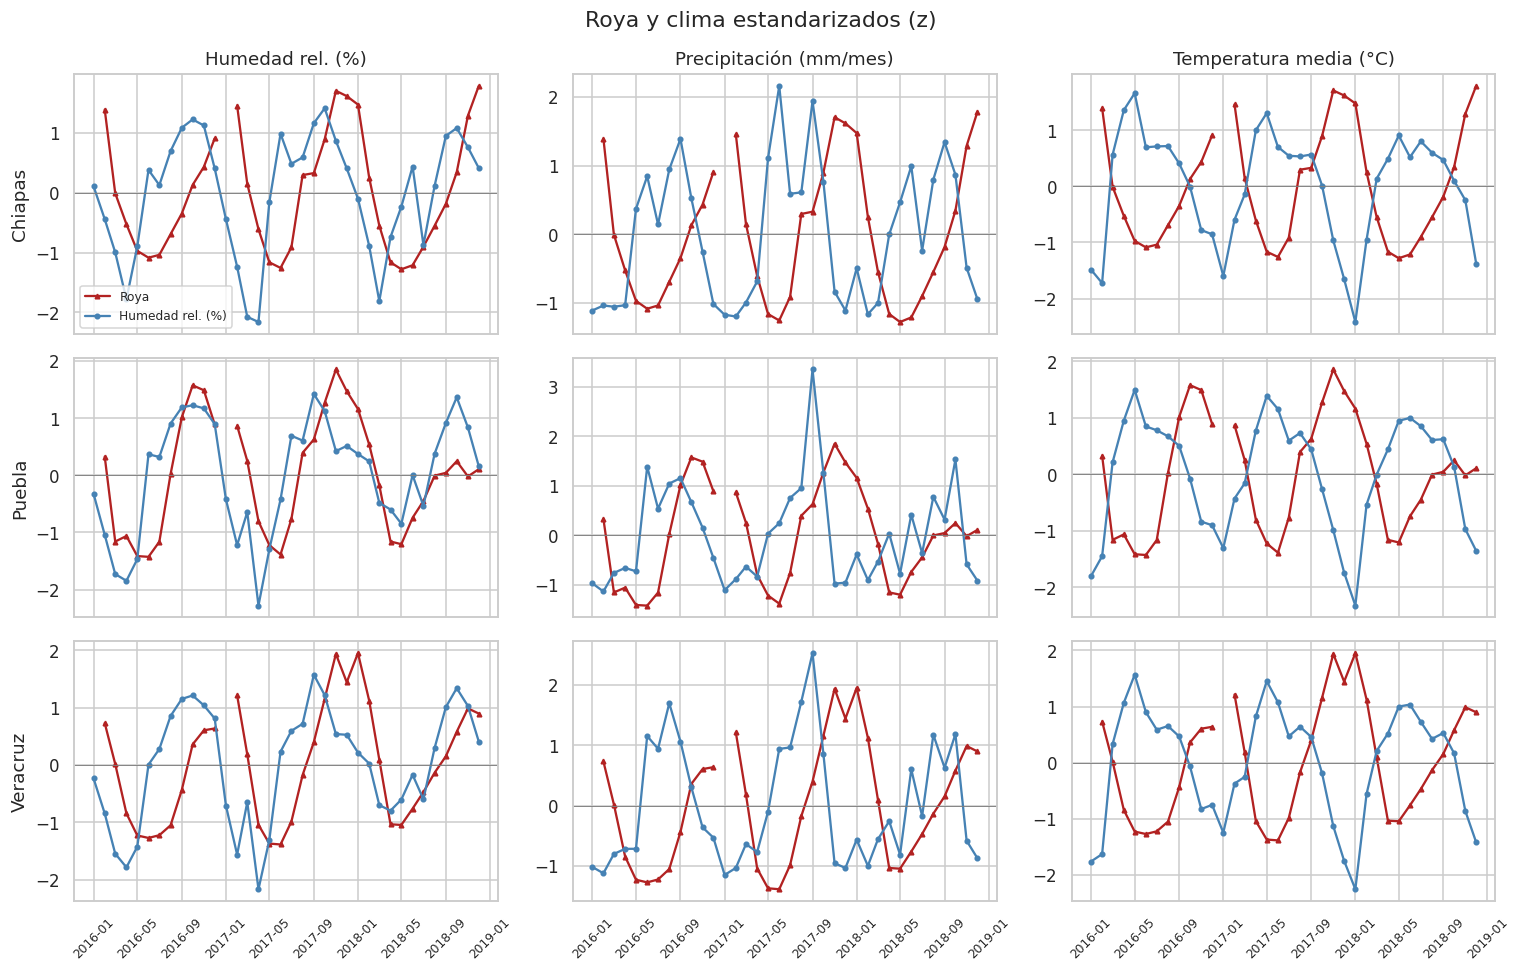

In [ ]:
estandarizar = lambda s: (s - s.mean()) / s.std()

fig, ejes = plt.subplots(3, 3, figsize=(14, 9), sharex=True)
for i, est in enumerate(ESTADOS):
    g = datos[datos.estado == est]
    for j, v in enumerate(VARS):
        ax = ejes[i, j]
        ax.plot(g.fecha, estandarizar(g.roya_planta), "^-", color="firebrick", ms=3, label="Roya")
        ax.plot(g.fecha, estandarizar(g[v]), "o-", color="steelblue", ms=3, label=NOMBRES[v])
        ax.axhline(0, color="gray", lw=.6)
        ax.tick_params(axis="x", rotation=45, labelsize=8)
        if i == 0: ax.set_title(NOMBRES[v])
        if j == 0: ax.set_ylabel(est)
ejes[0, 0].legend(fontsize=8)
fig.suptitle("Roya y clima estandarizados (z)")
fig.tight_layout(); plt.show()

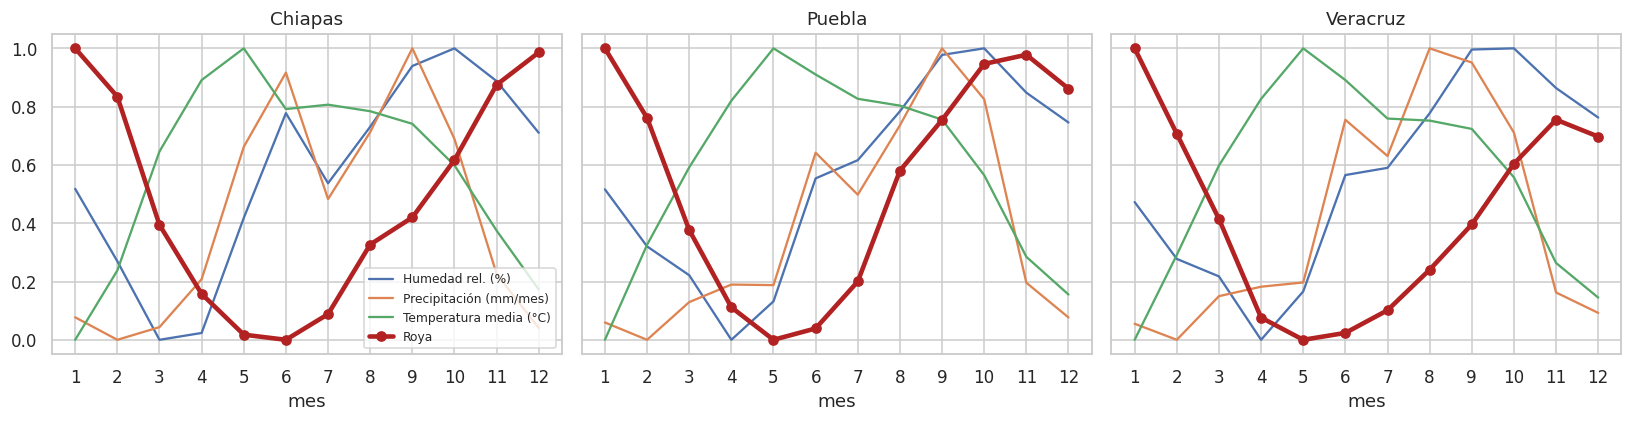

,pico_roya,pico_humedad,desfase_humedad,pico_precip,desfase_precip,pico_temp,desfase_temp
estado,,,,,,,
Chiapas,1,10,3,9,4,5,8
Puebla,1,10,3,9,4,5,8
Veracruz,1,10,3,8,5,5,8


In [ ]:
# ciclo del año: Roya y clima reescalados de 0 a 1
reescalar = lambda s: (s - s.min()) / (s.max() - s.min())
ciclo = datos.groupby(["estado", "mes"])[["roya_planta"] + VARS].mean()

fig, ejes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, est in zip(ejes, ESTADOS):
    c = ciclo.loc[est]
    for v in VARS:
        ax.plot(c.index, reescalar(c[v]), label=NOMBRES[v])
    ax.plot(c.index, reescalar(c.roya_planta), color="firebrick", lw=3, marker="o", label="Roya")
    ax.set_title(est); ax.set_xlabel("mes"); ax.set_xticks(range(1, 13))
ejes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

# mes del pico y desfase (meses entre el pico del clima y el de la Roya)
picos = []
for est in ESTADOS:
    c = ciclo.loc[est]
    mes_roya = int(c.roya_planta.idxmax())
    fila = {"estado": est, "pico_roya": mes_roya}
    for v in VARS:
        fila[f"pico_{v}"] = int(c[v].idxmax())
        fila[f"desfase_{v}"] = (mes_roya - fila[f"pico_{v}"]) % 12
    picos.append(fila)
pd.DataFrame(picos).set_index("estado")

In [ ]:
def bh(p):
    # corrección Benjamini-Hochberg
    p = np.asarray(p, float)
    q = np.full_like(p, np.nan)
    idx = np.where(~np.isnan(p))[0]
    orden = idx[np.argsort(p[idx])]
    aj = np.minimum.accumulate((p[orden] * len(idx) / np.arange(1, len(idx) + 1))[::-1])[::-1]
    q[orden] = np.minimum(aj, 1)
    return q

def correlaciones(datos, objetivo="roya_planta"):
    filas = []
    for est in ESTADOS:
        g = datos[datos.estado == est].sort_values("fecha")
        y = g[objetivo]
        n_mes = g.groupby("mes")[objetivo].transform("count")
        y_anom = (y - g.groupby("mes")[objetivo].transform("mean")).where(n_mes >= 2)
        for v in VARS:
            for k in LAGS:
                x, x_anom = g[f"{v}_{k}"], g[f"{v}_{k}_anom"]
                ok, ok_a = x.notna() & y.notna(), x_anom.notna() & y_anom.notna()
                rho, p = stats.spearmanr(x[ok], y[ok])
                rho_a, p_a = stats.spearmanr(x_anom[ok_a], y_anom[ok_a])
                filas.append((est, v, k, ok.sum(), rho, p, rho_a, p_a))
    t = pd.DataFrame(filas, columns=["estado", "var", "rezago", "n", "rho", "p", "rho_anom", "p_anom"])
    t["q"], t["q_anom"] = bh(t.p), bh(t.p_anom)
    return t

tabla = correlaciones(datos)
print("pruebas:", len(tabla), "| significativas (q<0.05):", (tabla.q < .05).sum(),
      "| sin estacionalidad:", (tabla.q_anom < .05).sum())

pruebas: 63 | significativas (q<0.05): 44 | sin estacionalidad: 0


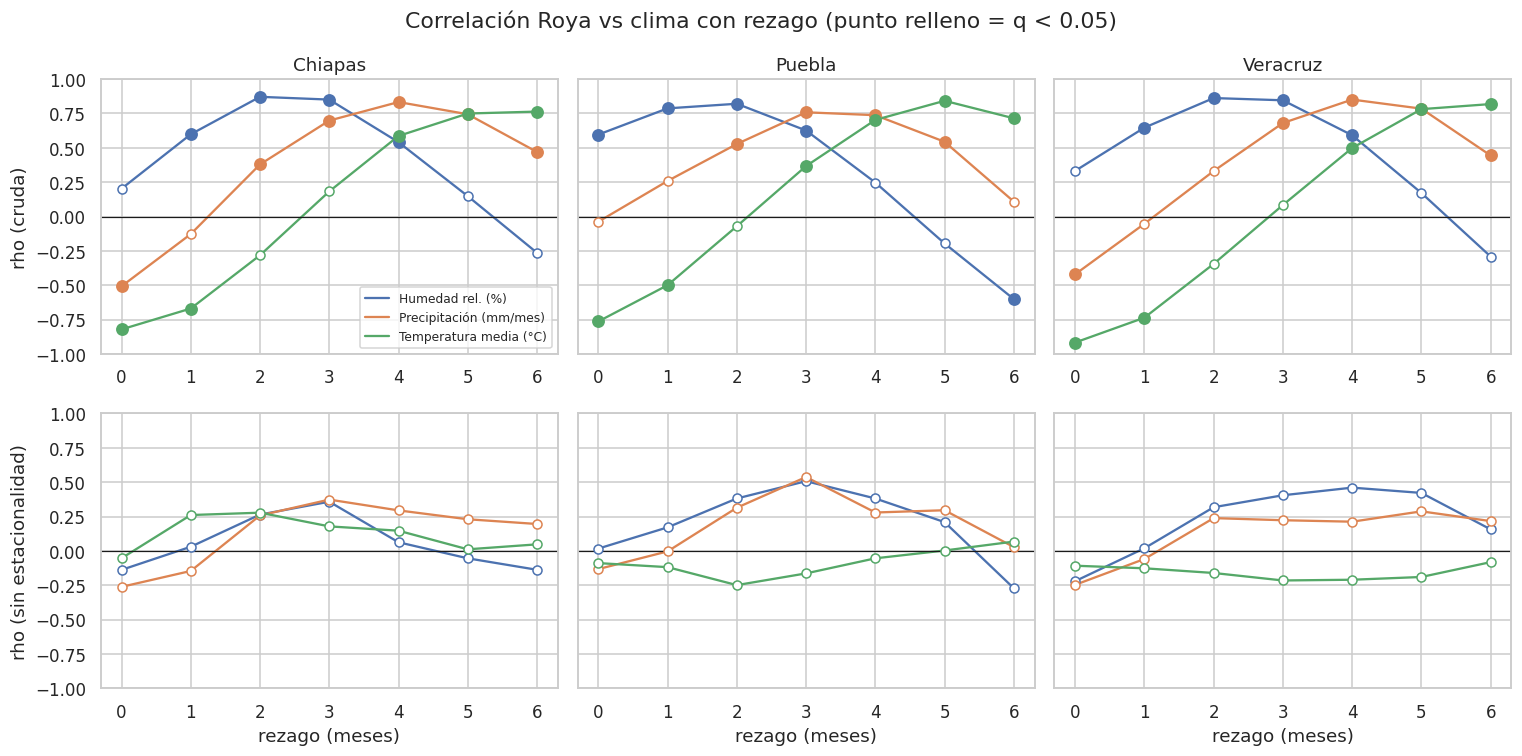

In [ ]:
colores = dict(zip(VARS, sns.color_palette("deep", 3)))

fig, ejes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for j, est in enumerate(ESTADOS):
    for i, (rho, q, titulo) in enumerate([("rho", "q", "cruda"), ("rho_anom", "q_anom", "sin estacionalidad")]):
        ax = ejes[i, j]
        for v in VARS:
            t = tabla[(tabla.estado == est) & (tabla["var"] == v)]
            ax.plot(t.rezago, t[rho], color=colores[v], label=NOMBRES[v])
            sig = t[t[q] < .05]
            ax.scatter(t.rezago, t[rho], s=35, facecolors="white", edgecolors=colores[v], zorder=3)
            ax.scatter(sig.rezago, sig[rho], s=55, color=colores[v], zorder=4)
        ax.axhline(0, color="k", lw=.8)
        ax.set_ylim(-1, 1)
        if i == 0: ax.set_title(est)
        if i == 1: ax.set_xlabel("rezago (meses)")
        if j == 0: ax.set_ylabel(f"rho ({titulo})")
ejes[0, 0].legend(fontsize=8)
fig.suptitle("Correlación Roya vs clima con rezago (punto relleno = q < 0.05)")
fig.tight_layout(); plt.show()

In [ ]:
# las más fuertes
tabla.assign(fuerza=tabla.rho.abs()).sort_values("fuerza", ascending=False).head(10)[
    ["estado", "var", "rezago", "n", "rho", "q", "rho_anom", "q_anom"]].round(3)

,estado,var,rezago,n,rho,q,rho_anom,q_anom
56,Veracruz,temp,0,34,-0.916,0.0,-0.108,0.737
2,Chiapas,humedad,2,34,0.871,0.0,0.264,0.443
44,Veracruz,humedad,2,34,0.862,0.0,0.318,0.431
53,Veracruz,precip,4,34,0.851,0.0,0.212,0.478
3,Chiapas,humedad,3,34,0.851,0.0,0.358,0.287
45,Veracruz,humedad,3,34,0.846,0.0,0.404,0.247
40,Puebla,temp,5,34,0.842,0.0,0.003,0.988
11,Chiapas,precip,4,34,0.833,0.0,0.294,0.443
14,Chiapas,temp,0,34,-0.821,0.0,-0.054,0.878
23,Puebla,humedad,2,34,0.820,0.0,0.381,0.256


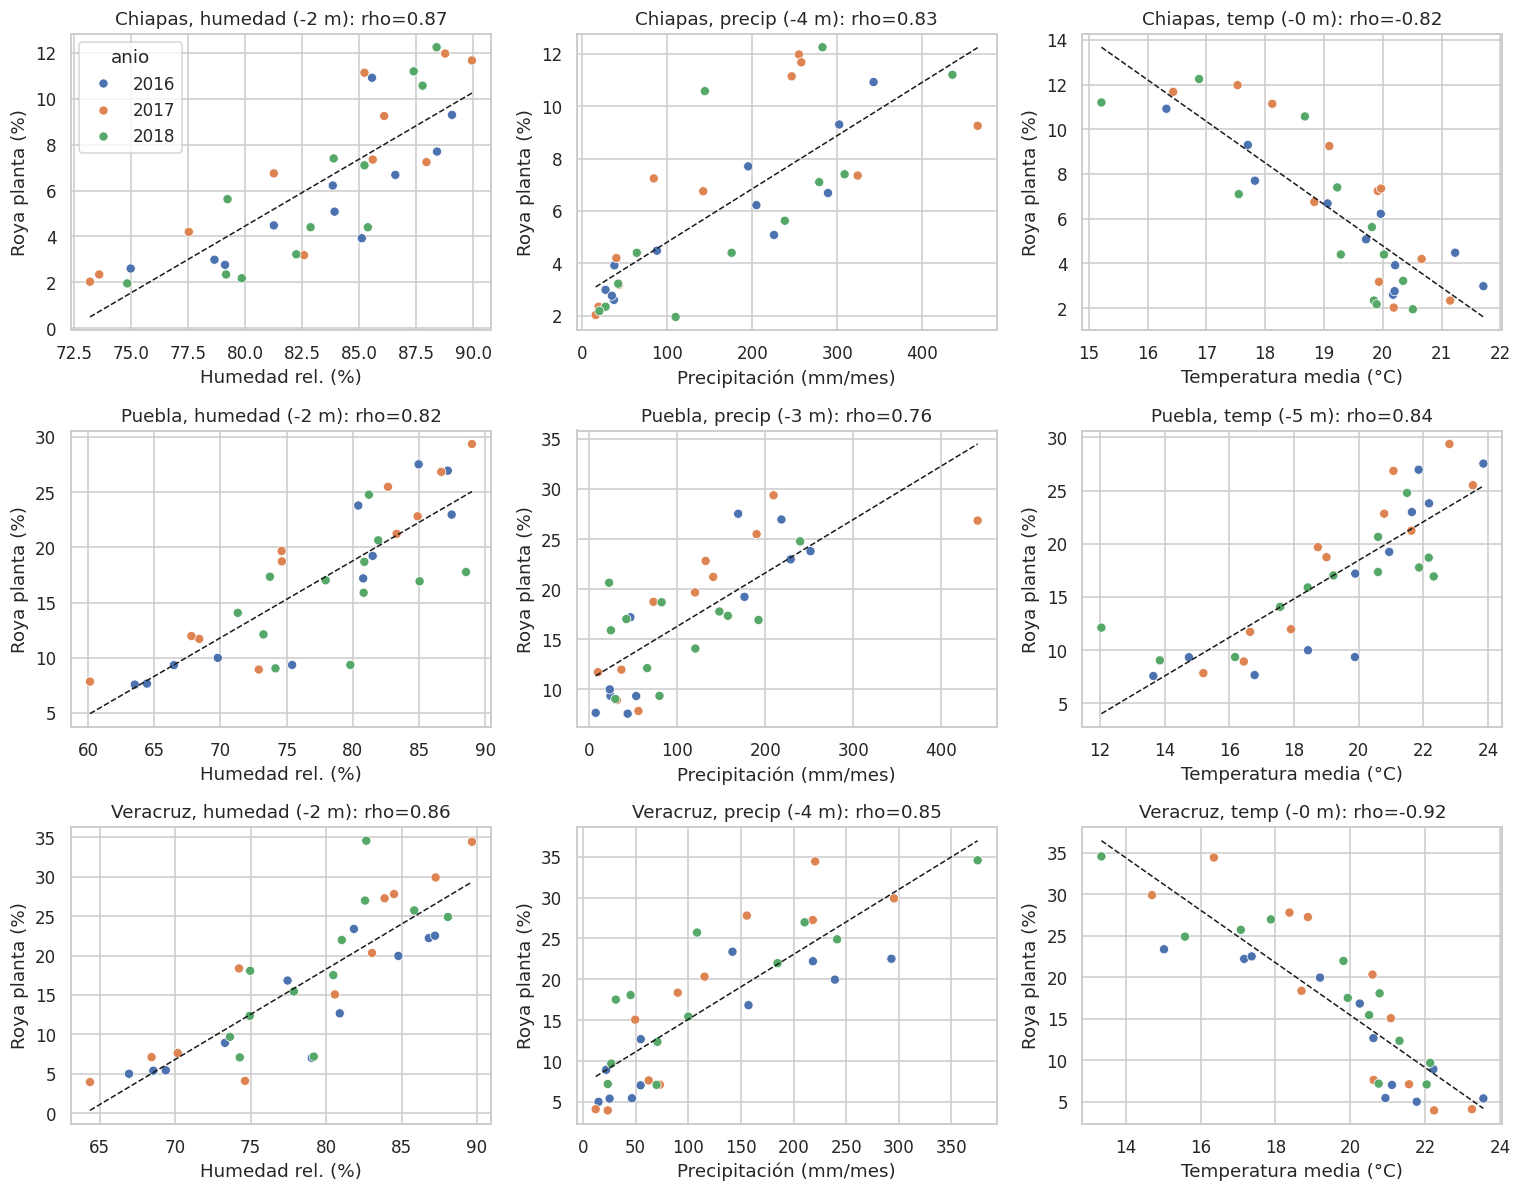

In [ ]:
# mejor rezago de cada variable (se elige viendo los datos, es exploratorio)
fig, ejes = plt.subplots(3, 3, figsize=(14, 11))
for i, est in enumerate(ESTADOS):
    g = datos[datos.estado == est]
    for j, v in enumerate(VARS):
        t = tabla[(tabla.estado == est) & (tabla["var"] == v)]
        mejor = t.loc[t.rho.abs().idxmax()]
        k = int(mejor.rezago)
        x, y = g[f"{v}_{k}"], g.roya_planta
        ok = x.notna() & y.notna()
        ax = ejes[i, j]
        sns.scatterplot(x=x[ok], y=y[ok], hue=g.anio[ok].astype(str), ax=ax, legend=(i == 0 and j == 0))
        r = stats.linregress(x[ok], y[ok])
        xs = np.linspace(x[ok].min(), x[ok].max(), 50)
        ax.plot(xs, r.intercept + r.slope * xs, "k--", lw=1)
        ax.set_title(f"{est}, {v} (-{k} m): rho={mejor.rho:.2f}")
        ax.set_xlabel(NOMBRES[v]); ax.set_ylabel("Roya planta (%)")
fig.tight_layout(); plt.show()

In [ ]:
# resumen por estado
for est in ESTADOS:
    t = tabla[tabla.estado == est]
    a = t.loc[t.rho.abs().idxmax()]
    b = t.loc[t.rho_anom.abs().idxmax()]
    print(est)
    print(f"  cruda:              {a['var']} a {int(a.rezago)} m, rho={a.rho:+.2f}, q={a.q:.3f}")
    print(f"  sin estacionalidad: {b['var']} a {int(b.rezago)} m, rho={b.rho_anom:+.2f}, q={b.q_anom:.3f}")

Chiapas
  cruda:              humedad a 2 m, rho=+0.87, q=0.000
  sin estacionalidad: precip a 3 m, rho=+0.37, q=0.256
Puebla
  cruda:              temp a 5 m, rho=+0.84, q=0.000
  sin estacionalidad: precip a 3 m, rho=+0.54, q=0.080
Veracruz
  cruda:              temp a 0 m, rho=-0.92, q=0.000
  sin estacionalidad: humedad a 4 m, rho=+0.46, q=0.149


## 4. Otras plagas vs clima

In [ ]:
# plagas de SENASICA, por estado y mes
# orden: mancha de hierro, ojo de gallo, phoma, minador, nematodo, factor daño
chiapas = [
 (0.00,0.01,0.00,0.11,0.00,0.12),(0.01,0.02,0.00,0.06,0.00,0.09),(0.01,0.01,0.00,0.08,0.00,0.10),
 (0.00,0.01,0.00,0.09,0.00,0.10),(0.00,0.01,0.00,0.09,0.09,0.11),(0.00,0.01,0.00,0.09,0.09,0.11),
 (0.00,0.01,0.00,0.09,0.09,0.11),(0.01,0.02,0.00,0.14,0.00,0.17),(0.00,0.02,0.00,0.13,0.00,0.15),
 (0.01,0.02,0.00,0.19,0.00,0.22),(0.00,0.00,0.00,0.20,0.00,0.24),(0.01,0.03,0.00,0.20,0.00,0.24),
 (0.01,0.01,0.00,0.04,0.00,0.06),(0.01,0.01,0.00,0.16,0.00,0.18),(0.01,0.01,0.00,0.15,0.00,0.17),
 (0.01,0.01,0.00,0.13,0.00,0.15),(0.01,0.00,0.00,0.14,0.00,0.15),(0.01,0.00,0.01,0.15,0.00,0.17),
 (0.00,0.01,0.00,0.14,0.00,0.15),(0.01,0.00,0.01,0.13,0.00,0.15),(0.01,0.01,0.02,0.14,0.00,0.18),
 (0.01,0.02,0.01,0.13,0.00,0.17),(0.02,0.01,0.00,0.14,0.00,0.17),(0.01,0.03,0.00,0.20,0.00,0.24),
 (0.01,0.02,0.00,0.11,0.00,0.14),(0.02,0.01,0.00,0.11,0.00,0.14),(0.01,0.01,0.00,0.11,0.00,0.13),
 (0.00,0.01,0.00,0.13,0.00,0.14),(0.00,0.01,0.00,0.14,0.00,0.15),(0.00,0.01,0.00,0.13,0.00,0.14),
 (0.00,0.02,0.00,0.16,0.00,0.18),(0.00,0.01,0.00,0.16,0.00,0.17),(0.00,0.01,0.00,0.18,0.00,0.19),
 (0.00,0.02,0.00,0.16,0.00,0.18),(0.00,0.01,0.00,0.16,0.00,0.17),(0.00,0.01,0.00,0.14,0.00,0.15),
]
puebla = [
 (0.05,0.01,0,0.00,0,0.06),(0.04,0.00,0,0.00,0,0.05),(0.05,0.01,0,0.00,0,0.06),
 (0.08,0.01,0,0.00,0,0.10),(0.03,0.01,0,0.00,0,0.03),(0.03,0.01,0,0.00,0,0.03),
 (0.03,0.01,0,0.00,0,0.03),(0.06,0.01,0,0.01,0,0.08),(0.05,0.01,0,0.01,0,0.07),
 (0.05,0.00,0,0.00,0,0.05),(0.06,0.01,0,0.00,0,0.07),(0.03,0.00,0,0.00,0,0.03),
 (0.02,0.01,0,0.00,0,0.03),(0.04,0.00,0,0.00,0,0.05),(0.03,0.01,0,0.00,0,0.04),
 (0.01,0.01,0,0.00,0,0.02),(0.06,0.00,0,0.01,0,0.06),(0.07,0.00,0,0.02,0,0.09),
 (0.08,0.01,0,0.01,0,0.10),(0.06,0.01,0,0.01,0,0.08),(0.06,0.01,0,0.02,0,0.09),
 (0.07,0.01,0,0.01,0,0.09),(0.06,0.01,0,0.01,0,0.08),(0.05,0.01,0,0.00,0,0.06),
 (0.07,0.01,0,0.00,0,0.08),(0.06,0.01,0,0.01,0,0.08),(0.06,0.01,0,0.01,0,0.08),
 (0.06,0.01,0,0.01,0,0.08),(0.07,0.01,0,0.01,0,0.09),(0.06,0.02,0,0.01,0,0.09),
 (0.08,0.01,0,0.01,0,0.10),(0.07,0.01,0,0.01,0,0.09),(0.07,0.01,0,0.01,0,0.09),
 (0.07,0.01,0,0.01,0,0.09),(0.06,0.01,0,0.01,0,0.08),(0.06,0.01,0,0.01,0,0.08),
]
veracruz = [
 (0.00,0.00,0.00,0.00,0,0.01),(0.00,0.00,0.00,0.01,0,0.01),(0.01,0.00,0.00,0.01,0,0.02),
 (0.06,0.01,0.04,0.03,0,0.13),(0.04,0.01,0.02,0.02,0,0.07),(0.04,0.01,0.02,0.02,0,0.07),
 (0.04,0.01,0.02,0.02,0,0.07),(0.03,0.00,0.01,0.03,0,0.07),(0.00,0.00,0.00,0.01,0,0.01),
 (0.03,0.00,0.00,0.06,0,0.09),(0.03,0.00,0.00,0.06,0,0.09),(0.01,0.05,0.00,0.01,0,0.07),
 (0.02,0.00,0.00,0.02,0,0.04),(0.02,0.01,0.00,0.02,0,0.02),(0.05,0.00,0.00,0.02,0,0.07),
 (0.05,0.00,0.00,0.02,0,0.07),(0.02,0.00,0.00,0.04,0,0.63),(0.01,0.00,0.00,0.07,0,0.08),
 (0.01,0.00,0.00,0.09,0,0.10),(0.02,0.00,0.00,0.10,0,0.12),(0.02,0.00,0.00,0.09,0,0.11),
 (0.02,0.00,0.00,0.09,0,0.11),(0.02,0.00,0.00,0.04,0,0.06),(0.02,0.00,0.00,0.03,0,0.05),
 (0.02,0.00,0.00,0.02,0,0.04),(0.04,0.00,0.00,0.03,0,0.07),(0.02,0.00,0.00,0.03,0,0.05),
 (0.01,0.00,0.00,0.03,0,0.04),(0.01,0.00,0.00,0.05,0,0.06),(0.01,0.00,0.00,0.07,0,0.08),
 (0.01,0.00,0.00,0.10,0,0.11),(0.01,0.00,0.00,0.10,0,0.11),(0.01,0.00,0.00,0.08,0,0.09),
 (0.01,0.00,0.00,0.09,0,0.10),(0.02,0.00,0.00,0.08,0,0.10),(0.01,0.00,0.00,0.08,0,0.09),
]

columnas = ["mancha_hierro", "ojo_gallo", "phoma", "minador", "nematodo", "factor_dano"]
fechas = pd.date_range("2016-01-01", periods=36, freq="MS")
partes = []
for estado, filas in zip(ESTADOS, [chiapas, puebla, veracruz]):
    partes.append(pd.DataFrame(filas, columns=columnas).assign(estado=estado, fecha=fechas))
plagas = pd.concat(partes, ignore_index=True)

# veracruz mayo 2017: factor daño 0.63 pero las plagas de ese mes suman 0.06, error de captura
fila = (plagas.estado == "Veracruz") & (plagas.fecha == "2017-05-01")
plagas.loc[fila, "factor_dano"] = 0.06

datos_p = datos.merge(plagas, on=["estado", "fecha"])
print(datos_p.shape)
plagas.groupby("estado")[columnas].mean().round(3)

(108, 57)


,mancha_hierro,ojo_gallo,phoma,minador,nematodo,factor_dano
estado,,,,,,
Chiapas,0.006,0.012,0.001,0.134,0.008,0.155
Puebla,0.054,0.009,0.000,0.006,0.000,0.069
Veracruz,0.021,0.003,0.003,0.046,0.000,0.071


In [ ]:
# phoma y nematodo casi siempre son 0, no sirven para correlacionar
OBJETIVOS = ["minador", "mancha_hierro", "ojo_gallo", "factor_dano"]

tablas = []
for obj in OBJETIVOS:
    tablas.append(correlaciones(datos_p, obj).assign(objetivo=obj))
tabla_p = pd.concat(tablas, ignore_index=True)

# la mejor combinación de cada plaga en cada estado
resumen = []
for (obj, est), t in tabla_p.groupby(["objetivo", "estado"]):
    t = t.dropna(subset=["rho", "rho_anom"])
    if len(t) == 0:
        continue
    a = t.loc[t.rho.abs().idxmax()]
    b = t.loc[t.rho_anom.abs().idxmax()]
    resumen.append({"plaga": obj, "estado": est,
                    "cruda": f"{a['var']} {int(a.rezago)}m", "rho": round(a.rho, 2), "q": round(a.q, 3),
                    "sin_estac": f"{b['var']} {int(b.rezago)}m", "rho_anom": round(b.rho_anom, 2), "q_anom": round(b.q_anom, 3)})
pd.DataFrame(resumen)

,plaga,estado,cruda,rho,q,sin_estac,rho_anom,q_anom
0,factor_dano,Chiapas,humedad 0m,0.53,0.014,temp 1m,-0.31,0.715
1,factor_dano,Puebla,humedad 4m,-0.36,0.095,temp 2m,-0.45,0.369
2,factor_dano,Veracruz,precip 1m,0.56,0.014,precip 5m,0.33,0.715
3,mancha_hierro,Chiapas,humedad 4m,0.48,0.074,temp 1m,-0.41,0.396
4,mancha_hierro,Puebla,precip 0m,0.33,0.335,temp 2m,-0.41,0.396
5,mancha_hierro,Veracruz,humedad 5m,0.24,0.427,humedad 2m,-0.34,0.893
6,minador,Chiapas,precip 2m,0.48,0.021,precip 5m,-0.33,0.771
7,minador,Puebla,humedad 4m,-0.55,0.013,temp 6m,-0.36,0.771
8,minador,Veracruz,precip 1m,0.57,0.013,temp 3m,-0.26,0.771
9,ojo_gallo,Chiapas,precip 4m,0.48,0.190,humedad 5m,0.38,0.448


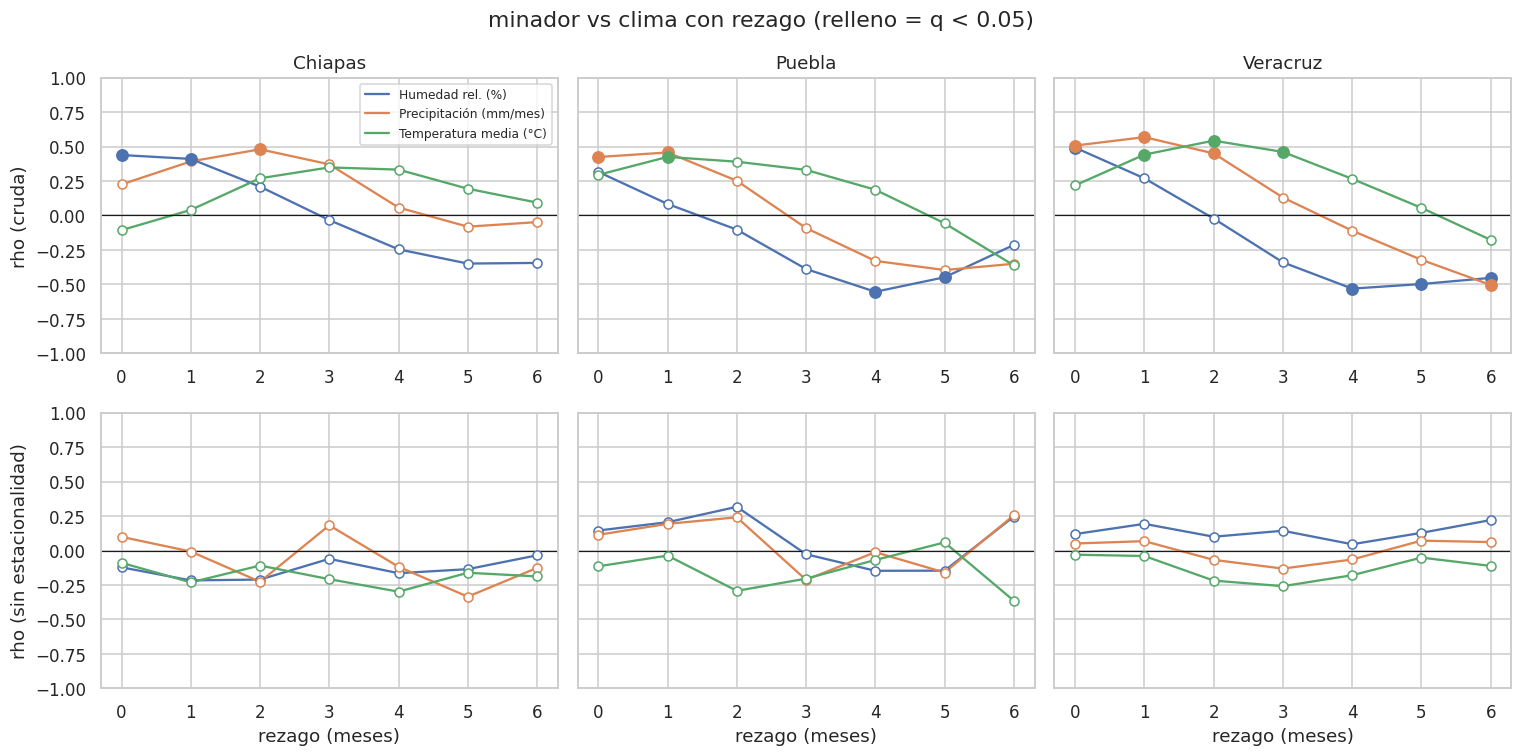

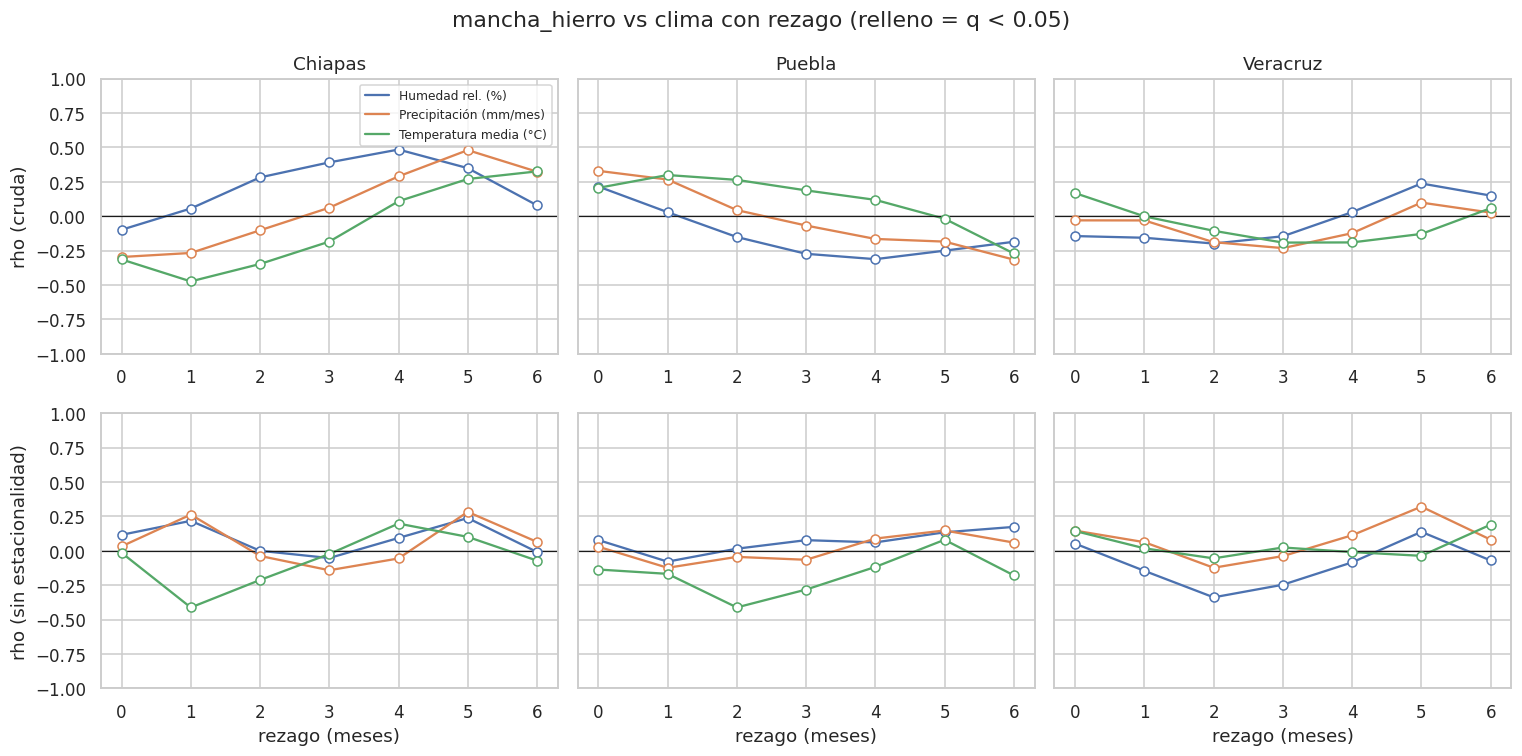

In [ ]:
def graficar_rezagos(t, titulo):
    fig, ejes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
    for j, est in enumerate(ESTADOS):
        for i, (rho, q, nombre) in enumerate([("rho", "q", "cruda"), ("rho_anom", "q_anom", "sin estacionalidad")]):
            ax = ejes[i, j]
            for v in VARS:
                d = t[(t.estado == est) & (t["var"] == v)]
                ax.plot(d.rezago, d[rho], color=colores[v], label=NOMBRES[v])
                sig = d[d[q] < .05]
                ax.scatter(d.rezago, d[rho], s=35, facecolors="white", edgecolors=colores[v], zorder=3)
                ax.scatter(sig.rezago, sig[rho], s=55, color=colores[v], zorder=4)
            ax.axhline(0, color="k", lw=.8)
            ax.set_ylim(-1, 1)
            if i == 0: ax.set_title(est)
            if i == 1: ax.set_xlabel("rezago (meses)")
            if j == 0: ax.set_ylabel(f"rho ({nombre})")
    ejes[0, 0].legend(fontsize=8)
    fig.suptitle(titulo)
    fig.tight_layout(); plt.show()

# las dos con más variación (minador en Chiapas y Veracruz, mancha de hierro en Puebla)
for obj in ["minador", "mancha_hierro"]:
    graficar_rezagos(tabla_p[tabla_p.objetivo == obj], f"{obj} vs clima con rezago (relleno = q < 0.05)")

## Conclusiones

**Roya y clima**
- La Roya sigue un ciclo muy marcado: baja entre mayo y junio y sube hacia el final del año. El pico sale en enero en los tres estados, pero enero solo tiene datos de 2018 (en 2016 y 2017 falta), así que es más correcto decir que está alta de noviembre a enero.
- La lluvia llega a su máximo en agosto o septiembre y la humedad en octubre. La Roya llega a su pico como 4 o 5 meses después de la lluvia (3 después de la humedad). Tiene sentido porque la enfermedad va creciendo poco a poco después de la temporada de lluvias.
- En la correlación normal salieron 44 de 63 pruebas significativas, pero casi todas son por el calendario, las dos cosas suben y bajan durante el año. La temperatura da correlación negativa (Veracruz, rho = -0.92) solo porque la Roya sube en diciembre y enero que es cuando hace más frío, no quiere decir que el frío la cause.
- Al quitar la estacionalidad (comparar cada mes contra el promedio de ese mes) ya no queda nada significativo, 0 de 63 con q < 0.05. Lo más cercano fue Puebla con la lluvia de 3 meses antes (rho = 0.54, q = 0.08), luego Veracruz con la humedad de 4 meses antes (0.46, q = 0.15) y Chiapas con la lluvia de 3 meses antes (0.37, q = 0.26). Las tres son positivas (meses más lluviosos o húmedos de lo normal, más Roya después) pero con tan pocos datos no se puede confirmar.
- Comparando años: 2017 tuvo la mayor lluvia de septiembre en los tres estados (Chiapas 435 mm, Puebla 441, Veracruz 375) y también la Roya más alta en noviembre (12.0, 29.4 y 34.4 %). Son solo 3 años, es una pista y no una prueba.
- En resumen, el clima explica sobre todo el ciclo del año de la Roya. Que un año con más lluvia traiga más Roya se ve en el sentido esperado, pero no se pudo comprobar estadísticamente.

**Otras plagas**
(completar con la tabla de la sección 4)

**Limitaciones**
- La Roya viene por estado y el clima de NASA es de zonas de ~50 km, con 2 puntos por estado. No es el clima de cada finca.
- Solo 34 meses por estado y 3 años. A enero de 2016 y enero de 2017 les falta la Roya.
- Son 63 pruebas por variable, por eso se corrigió con Benjamini-Hochberg. Además cada mes depende del anterior, así que los p-values salen un poco optimistas.
- En 3 meses había una semana en cero (sin muestreo) y se quitó para calcular el promedio del mes.

In [ ]:
#descargar los csv del clima
from google.colab import files
clima.to_csv("clima_por_estado_2015_2018.csv", index=False, encoding="utf-8-sig") #promedio mensual por estado
clima_puntos.to_csv("clima_por_punto_2015_2018.csv", index=False, encoding="utf-8-sig") #datos crudos

files.download("clima_por_estado_2015_2018.csv")
files.download("clima_por_punto_2015_2018.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>